# 1. Introducción: ¿cuántos sismos habrá el próximo mes en cada zona de Colombia?

**Autores:** Juan David Polo y Gabriella Pallares · Maestría en Ingeniería Industrial, Universidad del Norte.

Este libro reúne los dos entregables del proyecto de Machine Learning:

- **Entregable 1** (capítulos 1–12): base de datos, análisis exploratorio (EDA), auditoría de fuga,
  preprocesamiento y modelo base comparado con líneas base triviales.
- **Entregable 2** (capítulos 13 en adelante): modelos benchmark de clasificación y regresión,
  optimización de hiperparámetros con validación anidada, optimización computacional, evaluación,
  interpretabilidad, robustez y comparación estadística.

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

## Problema y pregunta de investigación

Colombia está sobre la convergencia de las placas de Nazca, Caribe y Sudamérica. La Red Sismológica
Nacional del Servicio Geológico Colombiano (SGC) registra decenas de sismos por día. Estos sismos no
ocurren al azar en el espacio ni en el tiempo: se concentran en fuentes conocidas, como el nido de
Bucaramanga, y se agrupan en secuencias de réplicas y enjambres.

**Pregunta.** Con la información del catálogo hasta el final del mes *t*, ¿cuántos sismos de magnitud
M ≥ 2,5 se registrarán durante el mes *t + 1* en cada celda de 0,5° × 0,5° del territorio colombiano?

**Utilidad práctica.** Un pronóstico mensual de actividad por zona sirve como insumo para:
- priorizar inspecciones y comunicaciones de riesgo;
- planear el mantenimiento de estaciones;
- fijar líneas base contra las cuales detectar actividad anómala.

No es una predicción determinista de terremotos. Es un pronóstico de **tasa de actividad**, en la
línea de los experimentos de pronóstico del CSEP {cite}`kagan2011global,zhuang2011next`.

## Variable objetivo y unidad de observación

- **Unidad de observación:** una celda activa de 0,5° (≈ 55 km × 55 km) en un mes.
- **Objetivo:** el número de sismos M ≥ 2,5 registrados en la celda durante el mes siguiente. Es un
  conteo entero ≥ 0, con muchos ceros y valores extremos durante los enjambres.
- **Predictoras:** solo información disponible al cierre del mes *t*. Se construyen con conteos
  recientes, magnitudes, profundidad, actividad de las celdas vecinas, estacionalidad y ubicación.

In [2]:
# Panel celda × mes y partición cronológica (entrenamiento, gap de un mes y prueba); resumen del tamaño del problema
ev_, X, info, tr, gp, te = datos.panel_completo()
y = info["y"]
fecha_tr_fin = datos.fecha_de_mes(info["tm"][tr].max())[0]
fecha_te_ini = datos.fecha_de_mes(info["tm"][te].min())[0]
fecha_te_fin = datos.fecha_de_mes(info["tm"][te].max())[0]
resumen = pd.DataFrame([
    ("Sismos en el catálogo limpio (M ≥ 2,5, 2004-01 a 2026-09)", es(len(ev_), 0)),
    ("Celdas activas (≥ 20 sismos antes del corte)", es(len(info["celdas"]), 0)),
    ("Meses objetivo", es(len(np.unique(info["tm"])), 0)),
    ("Filas del panel celda × mes", es(len(y), 0)),
    ("Predictoras del modelo base", X.shape[1]),
    ("Entrenamiento (meses objetivo)", f"{datos.fecha_de_mes(info['tm'][tr].min())[0]:%Y-%m} a {fecha_tr_fin:%Y-%m} · {es(len(tr), 0)} filas"),
    ("Gap (mes excluido)", f"{datos.fecha_de_mes(info['tm'][gp].min())[0]:%Y-%m} · {es(len(gp), 0)} filas"),
    ("Prueba (meses objetivo)", f"{fecha_te_ini:%Y-%m} a {fecha_te_fin:%Y-%m} · {es(len(te), 0)} filas"),
    ("Proporción de ceros del objetivo (entrenamiento)", es(np.mean(y[tr] == 0), 1, pct=True)),
], columns=["medida", "valor"])
eda.guardar_tabla(resumen, "resumen_proyecto.csv")
resumen

,medida,valor
0,"Sismos en el catálogo limpio (M ≥ 2,5, 2004-01...",40.365
1,Celdas activas (≥ 20 sismos antes del corte),163
2,Meses objetivo,260
3,Filas del panel celda × mes,42.380
4,Predictoras del modelo base,18
5,Entrenamiento (meses objetivo),2005-02 a 2020-11 · 30.970 filas
6,Gap (mes excluido),2020-12 · 163 filas
7,Prueba (meses objetivo),2021-01 a 2026-09 · 11.247 filas
8,Proporción de ceros del objetivo (entrenamiento),"76,3 %"


In [3]:
md(f"""**Interpretación.** El panel tiene **{es(len(y), 0)} filas** (celda × mes), por encima del mínimo de 20.000
observaciones del enunciado. El tamaño efectivo es menor que el número de filas: hay
**{len(info['celdas'])} celdas** (entidades) observadas durante **{len(np.unique(info['tm']))} meses**, y las celdas de un
mismo mes comparten el estado sísmico regional. Por eso todos los intervalos de confianza del libro
remuestrean **meses completos**, no filas.

El {es(np.mean(y[tr] == 0), 0, pct=True)} de las celdas-mes del entrenamiento tiene cero sismos. El objetivo es un
conteo inflado en ceros y con cola pesada, y esta propiedad decide la métrica principal.""")

**Interpretación.** El panel tiene **42.380 filas** (celda × mes), por encima del mínimo de 20.000
observaciones del enunciado. El tamaño efectivo es menor que el número de filas: hay
**163 celdas** (entidades) observadas durante **260 meses**, y las celdas de un
mismo mes comparten el estado sísmico regional. Por eso todos los intervalos de confianza del libro
remuestrean **meses completos**, no filas.

El 76 % de las celdas-mes del entrenamiento tiene cero sismos. El objetivo es un
conteo inflado en ceros y con cola pesada, y esta propiedad decide la métrica principal.

## Métrica principal: RMSLE

$$\mathrm{RMSLE}=\sqrt{\tfrac{1}{n}\sum_i\big(\log(1+\hat y_i)-\log(1+y_i)\big)^2}$$

- **Por qué RMSLE.** Con cerca de 76 % de ceros y enjambres de cientos de sismos, el RMSE queda dominado por
  unos pocos meses extremos, y un modelo puede «ganar» solo por acertar uno de ellos. El RMSLE mide el
  error relativo, que es lo que importa en un pronóstico de tasa: equivocarse por 5 sismos pesa
  distinto cuando se esperaban 2 que cuando se esperaban 200.
- **Por qué no MAPE.** Se indefine con y = 0. Se reporta restringido a y > 0, junto con el sMAPE, como
  métrica complementaria.
- **Métricas complementarias:** RMSE, MAE, R² y R² en escala log (capítulo 11).
- **Decisión previa.** La métrica se fijó **antes** de ver la prueba, por la naturaleza del objetivo.
  No se cambia después para favorecer a ningún modelo.

## Fuente, licencia y alcance de los datos

- **Fuente:** catálogo de sismos de la **Red Sismológica Nacional de Colombia** (SGC). Se descargó en
  diez archivos de sus dos portales de consulta:
  - el portal histórico ([sismologia.sgc.gov.co](http://www.sismologia.sgc.gov.co/)): archivos
    `reporte*.xlsx`, de 2004 a febrero de 2018;
  - el portal actual ([sgc.gov.co/sismos](https://www.sgc.gov.co/sismos)): archivos
    `Catalogo_Sismico*.csv`, de marzo de 2018 a octubre de 2026.

  Los diez archivos crudos se incluyen en `data/crudos/`. El capítulo 2 documenta la ETL que los
  convierte en `data/sismos_sgc_2004_2026.csv`.
- **Licencia:** no encontramos una licencia específica para el catálogo (por ejemplo, Creative
  Commons). Los [términos generales de uso de información del SGC](https://www2.sgc.gov.co/sgc/mapas/Documents/CondGenTermLicUso.pdf)
  exigen citar la fuente y prohíben comercializar o redistribuir los datos sin autorización escrita. El
  uso en este proyecto es académico, sin fines comerciales y con atribución.
- **Alcance:** sismos M ≥ 2,5 atribuidos a un departamento colombiano. Los eventos en el mar o en zonas
  fronterizas sin departamento quedan fuera (capítulo 2, sesgos).

## Ruta del enunciado

El objetivo es continuo (un conteo) y el dataset tiene fecha y coordenadas. Por eso el trabajo sigue la
**ruta D (regresión espacio-temporal)** de la Figura 1 del enunciado, que incluye la C (temporal).
Eso implica:

- EDA temporal (cap. 7), espacial y espacio-temporal (cap. 8);
- partición cronológica con gap; validación cruzada temporal de ventana creciente, con validación por
  bloques espaciales como esquema adicional (cap. 11);
- Pipeline con rezagos temporales y espaciales, celdas y componentes cíclicos (cap. 10);
- líneas base: **persistencia por celda**, **media por celda (zona)**, **ingenuo estacional**,
  `DummyRegressor` y **SVR lineal**;
- métricas RMSE, MAPE y R², y diagnóstico de residuos con ACF e I de Moran.

## Partición entrenamiento / prueba (reservada antes del EDA)

- **Cuándo se definió.** Antes de cualquier decisión basada en los datos se reservaron como **prueba**
  todos los meses objetivo desde **enero de 2021**, unos seis años.
- **Gap.** Entre el último mes objetivo de entrenamiento (noviembre de 2020) y la prueba se deja **un mes
  de separación**. Las variables de diciembre de 2020 usan sismos que en el entrenamiento serían
  objetivo, y así ningún sismo aparece a la vez como objetivo en un conjunto y como predictora en el
  otro.
- **Qué se calcula solo con entrenamiento.** Todas las decisiones de modelado: celdas activas,
  imputación, escalado, umbrales e hiperparámetros.
- **Qué ven los capítulos del EDA.** Solo eventos y filas del entrenamiento. La única excepción, que se
  indica explícitamente, son las comparaciones de deriva entrenamiento/prueba de los capítulos 7 y 9,
  que no alimentan ninguna decisión.
- **Cortes adicionales.** Los cortes de 2018 y 2023 se usan solo como análisis de robustez del
  Entregable 2.

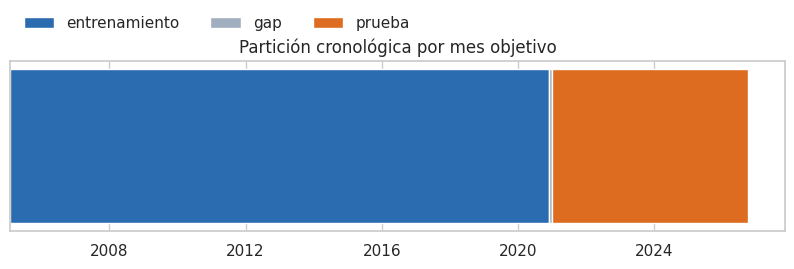

In [4]:
# Línea de tiempo de la partición: qué meses objetivo caen en entrenamiento, gap y prueba
fig, ax = plt.subplots(figsize=(10, 2.2))
meses_obj = datos.fecha_de_mes(np.unique(info["tm"]))
for nombre, idx, color in (("entrenamiento", tr, "#2b6cb0"), ("gap", gp, "#a0aec0"), ("prueba", te, "#dd6b20")):
    m = datos.fecha_de_mes(np.unique(info["tm"][idx]))
    ax.barh(0, (m.max() - m.min()).days + 31, left=m.min(), color=color, label=nombre)
ax.set_yticks([]); ax.legend(loc="upper left", ncol=3, frameon=False, bbox_to_anchor=(0, 1.35))
ax.set_title("Partición cronológica por mes objetivo")
eda.guardar_figura(fig, "01_particion.png"); plt.show()

## Mapa de capítulos

| Parte | Capítulos |
|---|---|
| Base de datos | 2. ETL, diccionario, estructura, calidad, sesgos y ética |
| EDA | 3. Objetivo · 4. Univariado · 5. Bivariado · 6. Multivariado · 7. Temporal · 8. Espacial y espacio-temporal · 9. Auditoría de fuga |
| Modelado (Entregable 1) | 10. Preprocesamiento (Pipeline) · 11. Modelo base · 12. Conclusiones del Entregable 1 |
| Entregable 2 | 13 en adelante (ver índice) |

## Consideraciones éticas (resumen)

- **Sin datos personales.** El catálogo no tiene datos de personas: cada fila es un fenómeno natural,
  así que no hay riesgo de reidentificación.
- **Riesgo de mal uso.** El riesgo ético está en **cómo se comunica** un pronóstico: presentar una tasa
  esperada como predicción de un terremoto puede generar alarma o falsa tranquilidad. El libro habla
  siempre de **tasas de actividad** con incertidumbre, nunca de predicción de eventos individuales.
- **Detalle completo:** capítulo 2.